# Experiment 01: lgbm vs lgbm_building

**Question:** does LightGBM improve when it knows which building a row comes from, and by how much?

Card: [exp01_building.md](../experiments/exp01_building.md).

- **lgbm:** LightGBM on the 33 features the MLP uses ([ashrae/features.py](../../ashrae/features.py)), untuned (500 trees,
  learning rate 0.1, 63 leaves).
- **lgbm_building:** the same plus `building_id` as a categorical feature, which LightGBM splits on directly.

Same 4 seasonal folds as every notebook, 2M training / 500K validation rows each, anomalies dropped from training only
([data.split](../../ashrae/data.py)). Every run is logged to MLflow, experiment `ashrae-baseline-building`. No torch here,
so LightGBM uses all cores (first run in [ensemble.ipynb](../../ensemble/notebooks/ensemble.ipynb) with one thread).


In [1]:
import sys
from time import perf_counter, strftime

import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MLFLOW_URI
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.tracking import log_run

EXPERIMENT = "ashrae-baseline-building"
SESSION = strftime("%Y-%m-%d %H:%M:%S")  # tag shared by this execution's runs
N_TRAIN, N_VAL = 2_000_000, 500_000  # rows sampled per fold, as in the other notebooks
LGBM_PARAMS = {"n_estimators": 500, "learning_rate": 0.1, "num_leaves": 63}
MODELS = ["lgbm", "lgbm_building"]

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Training

Per fold: both models on the same rows. Validation predictions are clipped at 0, like the metric. Logged per run:
validation RMSLE on all rows, on clean rows and per meter, training RMSLE, and training time.


In [ ]:
df = read_processed()
BUILDING = pd.CategoricalDtype(
    range(int(df.building_id.max()) + 1)
)  # all ids, so every fold shares categories


def with_building(X, rows):
    """`X` plus `building_id` as a categorical, which LightGBM splits on directly."""
    return X.assign(
        building_id=rows.building_id.astype(int).astype(BUILDING).to_numpy()
    )


for fold, months in FOLDS.items():
    train_df, val_df = split(df, months, N_TRAIN, N_VAL)
    year_median = train_df.year_built.median()
    X_train, X_val = build_features(train_df, year_median), build_features(
        val_df, year_median
    )
    y_train = np.log1p(train_df.meter_reading.to_numpy(dtype="float32"))
    y_val = np.log1p(val_df.meter_reading.to_numpy(dtype="float32"))
    clean = ~val_df.anomaly.to_numpy()
    for name in MODELS:
        Xtr, Xv = (
            (with_building(X_train, train_df), with_building(X_val, val_df))
            if name == "lgbm_building"
            else (X_train, X_val)
        )
        start = perf_counter()
        model = lgb.LGBMRegressor(**LGBM_PARAMS, random_state=0, verbose=-1).fit(
            Xtr, y_train
        )
        train_seconds = perf_counter() - start
        pred = np.clip(model.predict(Xv), 0, None)
        metrics = {
            **rmsle_by_meter(y_val, pred, val_df.meter.to_numpy()),
            "val_rmsle_clean": rmsle(y_val[clean], pred[clean]),
            "train_rmsle": rmsle(y_train, model.predict(Xtr)),
            "train_seconds": train_seconds,
        }
        log_run(
            EXPERIMENT,
            f"{name} | {fold}",
            params={
                **LGBM_PARAMS,
                "n_train": N_TRAIN,
                "n_val": N_VAL,
                "n_features": Xtr.shape[1],
            },
            metrics=metrics,
            tags={
                "session": SESSION,
                "fold": fold,
                "model": name,
                "notebook": "exp01_building",
            },
        )
        print(
            f"{fold} {name:14s} val RMSLE {metrics['val_rmsle']:.3f} (clean rows {metrics['val_rmsle_clean']:.3f}), "
            f"{train_seconds:.0f} s"
        )

2026/10/11 11:16:31 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-baseline-building' does not exist. Creating a new experiment.


Jan–Mar lgbm           val RMSLE 1.487 (clean rows 1.049), 10 s


Jan–Mar lgbm_building  val RMSLE 1.434 (clean rows 0.951), 10 s


Apr–Jun lgbm           val RMSLE 1.297 (clean rows 1.005), 10 s


Apr–Jun lgbm_building  val RMSLE 1.231 (clean rows 0.909), 10 s


Jul–Sep lgbm           val RMSLE 1.172 (clean rows 1.050), 10 s


Jul–Sep lgbm_building  val RMSLE 1.087 (clean rows 0.952), 10 s


Oct–Dec lgbm           val RMSLE 1.164 (clean rows 1.078), 10 s


Oct–Dec lgbm_building  val RMSLE 1.116 (clean rows 1.024), 10 s


## Results

Read from MLflow, the latest session of this notebook, so this section runs without retraining. The figure is saved to
[figures/](../figures/exp01_building.png) and logged as an artifact of each run.


In [ ]:
mlflow.set_tracking_uri(MLFLOW_URI)
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT], filter_string="tags.notebook = 'exp01_building'"
)
runs = runs[runs["tags.session"] == runs["tags.session"].max()]
results = runs.rename(
    columns=lambda c: c.removeprefix("metrics.").removeprefix("tags.")
)
print(f"MLflow session {results.session.iloc[0]}: {len(results)} runs")

table = results.pivot(index="model", columns="fold", values="val_rmsle").loc[
    MODELS, list(FOLDS)
]
averages = results.groupby("model")[
    ["val_rmsle", "val_rmsle_clean", "train_rmsle"]
].mean()
table["average"] = averages.val_rmsle
table["average, clean rows"] = averages.val_rmsle_clean
table["training"] = averages.train_rmsle
display(table.round(3).rename_axis("RMSLE, all rows unless noted"))

meters = (
    results.groupby("model")[[f"val_rmsle_{name}" for name in METERS.values()]]
    .mean()
    .loc[MODELS]
)
display(
    meters.rename(columns=lambda c: c.removeprefix("val_rmsle_"))
    .round(3)
    .rename_axis("fold average, all rows")
)

MLflow session 2026-10-11 11:16:15: 8 runs


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",training
"RMSLE, all rows unless noted",,,,,,,
lgbm,1.487,1.297,1.172,1.164,1.280,1.045,0.916
lgbm_building,1.434,1.231,1.087,1.116,1.217,0.959,0.815


,electricity,chilledwater,steam,hotwater
"fold average, all rows",,,,
lgbm,1.019,1.501,1.647,1.625
lgbm_building,0.975,1.392,1.560,1.583


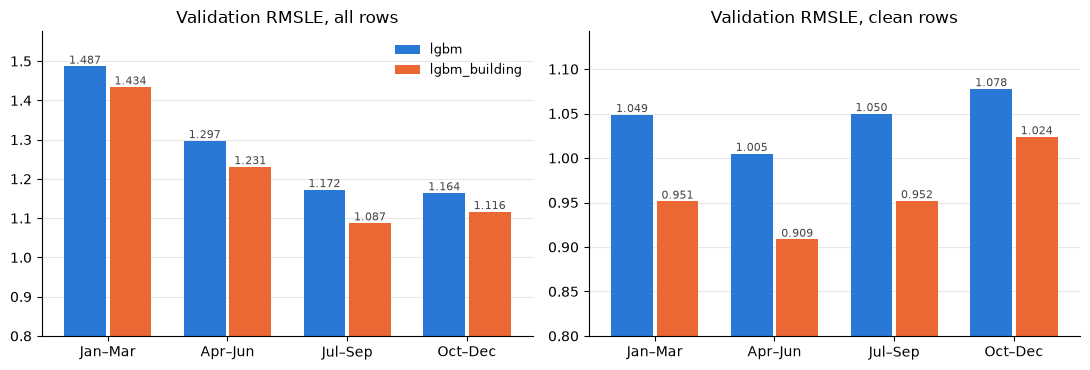

In [ ]:
COLORS = {"lgbm": "#2a78d6", "lgbm_building": "#eb6834"}
x, width = np.arange(len(FOLDS)), 0.38
BASE = 0.8  # bars start here, so the differences between models are visible
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, rows in zip(
    axes, ["val_rmsle", "val_rmsle_clean"], ["all rows", "clean rows"]
):
    scores = results.pivot(index="fold", columns="model", values=key).loc[
        list(FOLDS), MODELS
    ]
    for i, name in enumerate(MODELS):
        bars = ax.bar(
            x + (i - 0.5) * width,
            scores[name] - BASE,
            width - 0.03,
            bottom=BASE,
            color=COLORS[name],
            label=name,
        )
        ax.bar_label(
            bars, labels=[f"{v:.3f}" for v in scores[name]], fontsize=8, color="#444"
        )
    ax.set(
        xticks=x,
        xticklabels=list(FOLDS),
        ylim=(BASE, scores.to_numpy().max() * 1.06),
        title=f"Validation RMSLE, {rows}",
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
fig.savefig("../figures/exp01_building.png", dpi=150, bbox_inches="tight")

# The figure covers the whole experiment, so every run of this session gets a copy
client = mlflow.MlflowClient()
for run_id in runs.run_id:
    client.log_artifact(run_id, "../figures/exp01_building.png")

## Findings

Fold averages on all rows unless noted. Scores match the first run in
[ensemble.ipynb](../../ensemble/notebooks/ensemble.ipynb) to 3 decimals, though LightGBM now uses all cores.

- **The building helps in every fold:** lgbm 1.280 → lgbm_building 1.217 (−0.063), clean rows 1.045 → 0.959 (−0.086).
  Per fold −0.048 (Oct–Dec) to −0.085 (Jul–Sep).
- **Most on chilled water and steam:** −0.109 and −0.087, against −0.044 for electricity and −0.042 for hot water.
- **Training RMSLE** drops 0.916 → 0.815, so the gap to validation grows a little (0.36 → 0.40).

One seed per run; all differences above are larger than the ~0.01 noise level.
